# Random Forest

In [1]:
# %pip install scikit-learn matplotlib seaborn

In [2]:
# Dataset: http://kaggle.com/datasets/johnsmith88/heart-disease-dataset
# Download latest dataset
# import kagglehub
# path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")
# print("Path to dataset files:", path)

In [3]:
# Attribute Information:
# age
# sex
# resting blood pressure
# serum cholestoral in mg/dl
# target: refers to the presence of heart disease in the patient (0 = no disease, 1 = disease)

   age  sex   BP  cholestoral  heart_disease
0   52    1  125          212              0
1   53    1  140          203              0
2   70    1  145          174              0
3   61    1  148          203              0
4   62    0  138          294              0


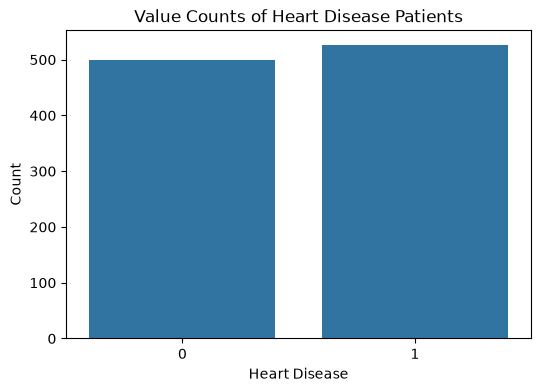

In [2]:
# Importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Import the dataset
df = pd.read_csv('heart.csv')[["age", "sex", "trestbps", "chol", "target"]]

# Rename columns
df.columns = ["age", "sex", "BP", "cholestoral", "heart_disease"]

# Display first 5 rows
print(df.head())

# Plot value counts of heart disease
plt.figure(figsize=(6, 4))
sns.countplot(x='heart_disease', data=df)
plt.title('Value Counts of Heart Disease Patients')
plt.xlabel('Heart Disease')
plt.ylabel('Count')
plt.show()


In [3]:
df.size

5125

In [4]:
# 3. Putting feature variables into X and target variable into y

# Feature variables
X = df.drop('heart_disease', axis=1)

# Target variable
y = df['heart_disease']


# 4. Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)


(717, 4) (308, 4)


In [17]:
# 5. Import RandomForestClassifier and fit the data

from sklearn.ensemble import RandomForestClassifier

classifier_rf = RandomForestClassifier(
    n_estimators=10,
    random_state=42
)

# Train the model
classifier_rf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = classifier_rf.predict(X_test)

from sklearn.metrics import accuracy_score

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy is:", accuracy)

Accuracy is: 0.9545454545454546


In [8]:
print(y_test)

289    0
428    0
138    1
262    1
457    1
      ..
913    1
200    1
517    1
88     0
893    0
Name: heart_disease, Length: 308, dtype: int64


In [6]:
y_pred

array([0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1,

In [10]:
# 6. Hyperparameter tuning for Random Forest using GridSearchCV

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Base model
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Parameter grid
params = {
    # 'max_depth': [2, 3, 5, 10],
    # 'min_samples_leaf': [5, 10, 20, 50, 100, 200],
    # 'n_estimators': [10, 25, 30, 50, 100, 200],
    'max_depth': [2, 3],
    'min_samples_leaf': [5, 10],
    'n_estimators': [10, 25, 30]
}

# Instantiate GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=4,
    n_jobs=-1,
    verbose=1,
    scoring='accuracy'
)

# Fit on training data
grid_search.fit(X_train, y_train)

# Best results
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

# Evaluate best model on test data
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Fitting 4 folds for each of 12 candidates, totalling 48 fits
Best Parameters: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 25}
Best CV Accuracy: 0.7113283674736188
Accuracy: 0.685064935064935


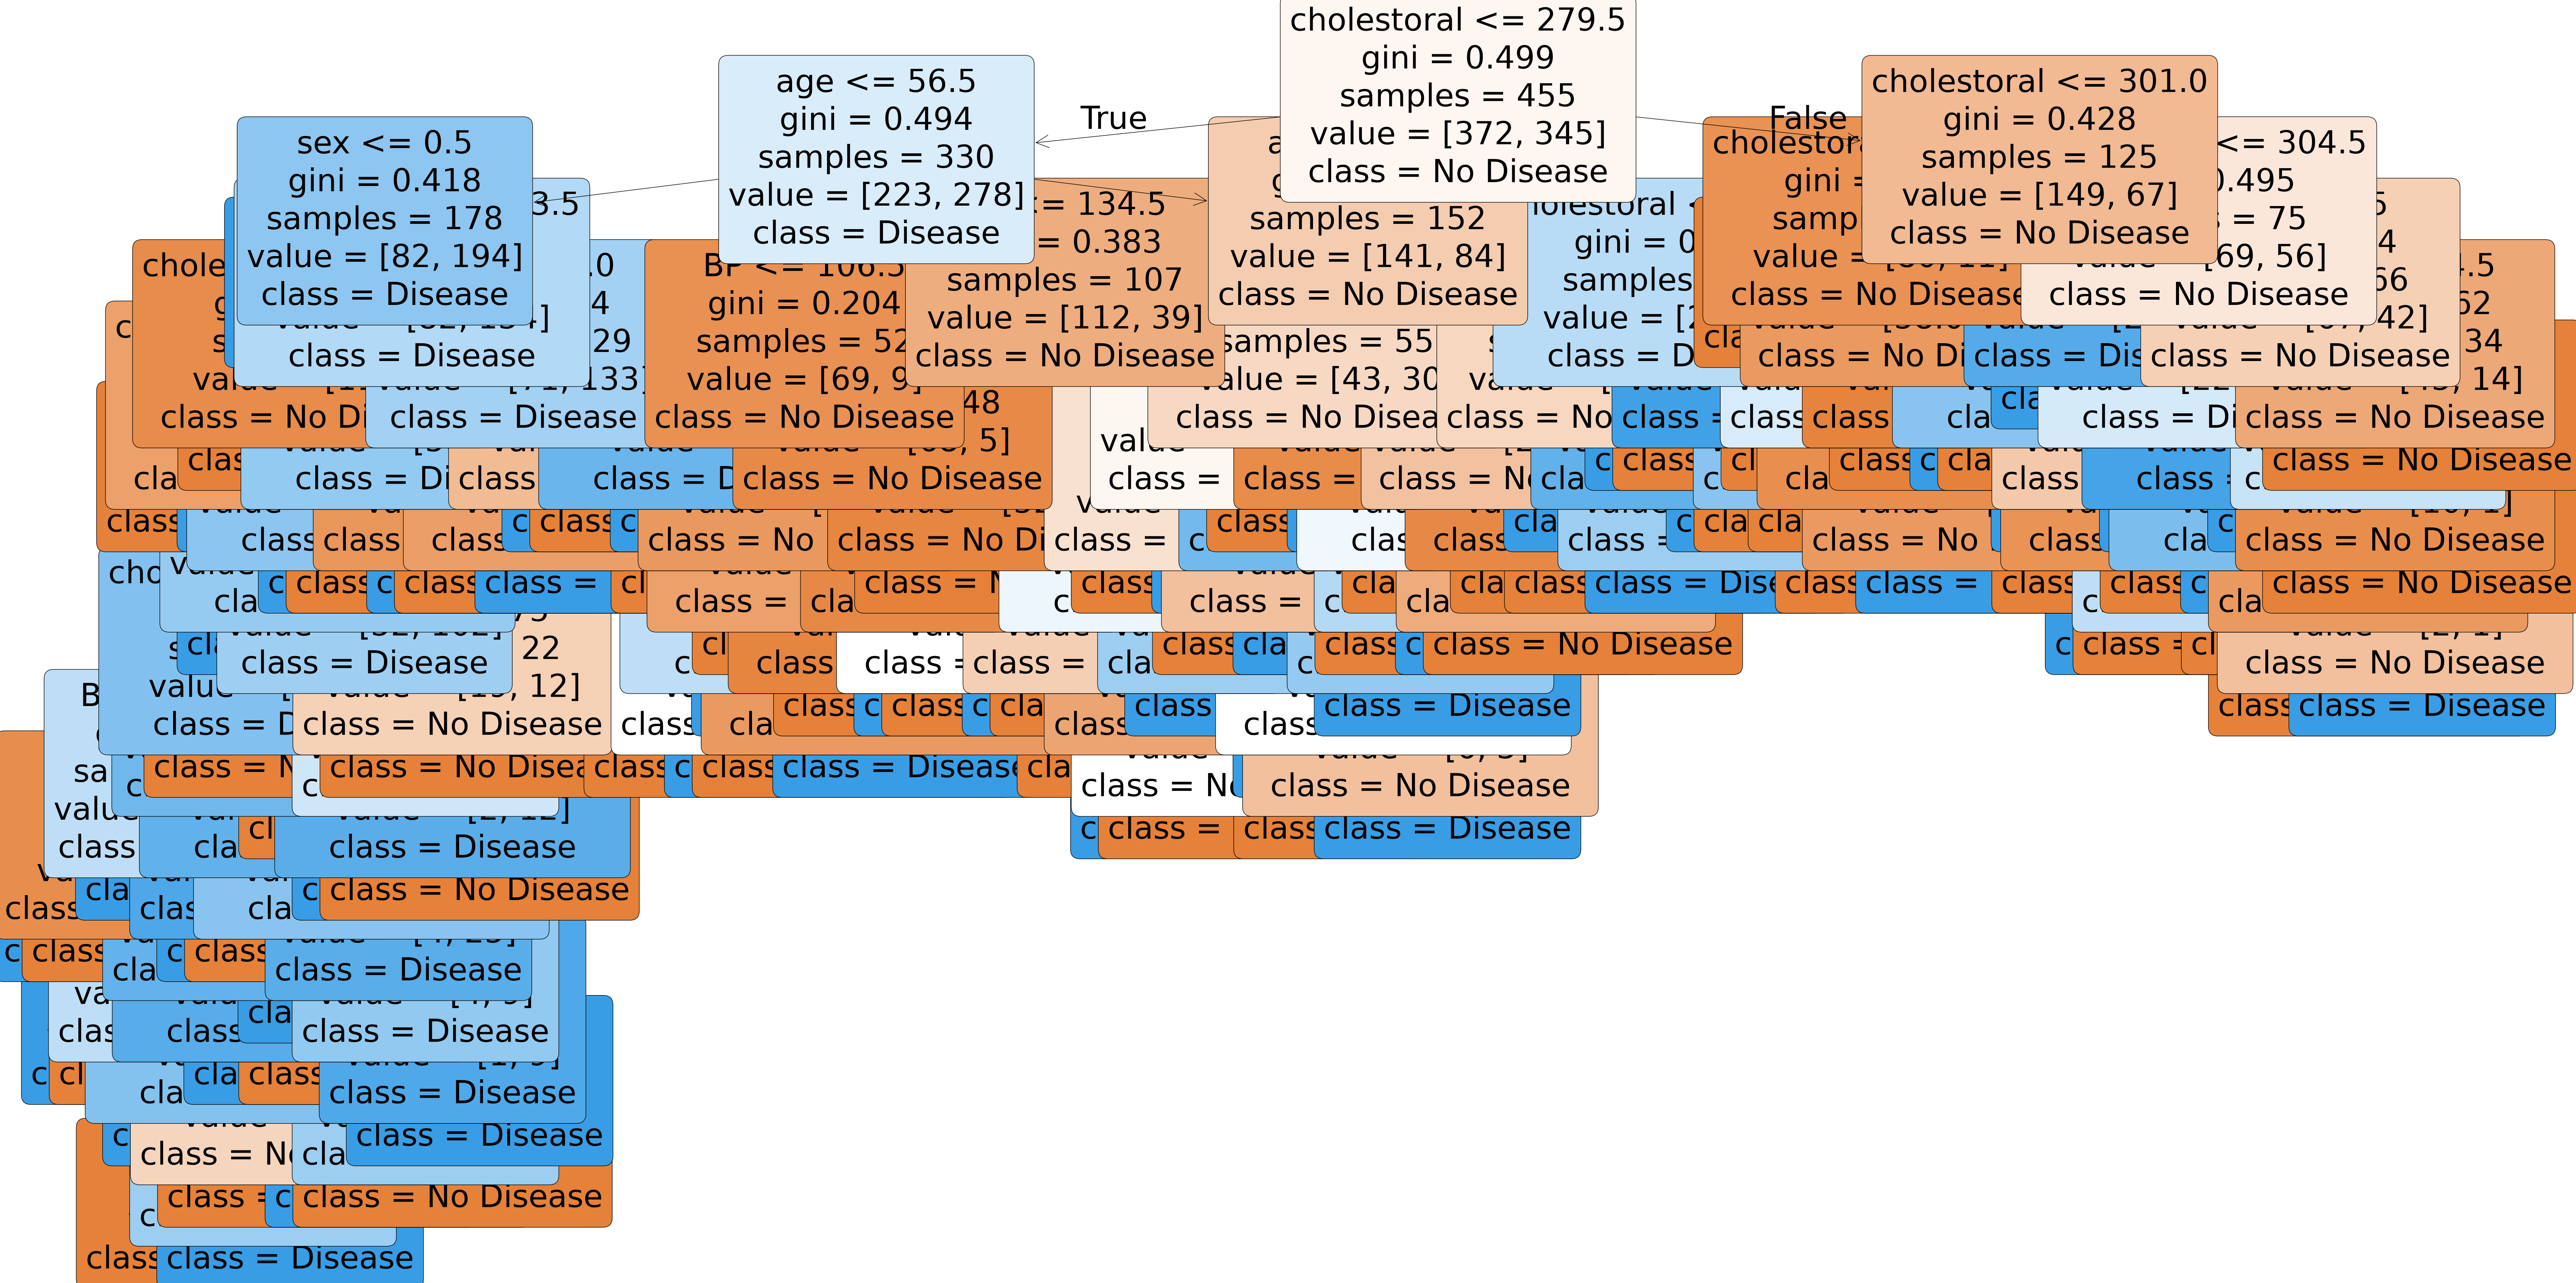

In [20]:
# 7. Visualize a tree from the Random Forest

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Plot one tree from the best Random Forest model
plt.figure(figsize=(80, 40))

plot_tree(
    classifier_rf.estimators_[5],     # choose any tree index
    feature_names=X.columns,
    class_names=['No Disease', 'Disease'],
    filled=True,                   # color nodes
    rounded=True,                  # rounded boxes
    fontsize=60
)

plt.show()



In [18]:
# 8. Sort the data using feature importance

import pandas as pd

# Create DataFrame of feature importances
imp_df = pd.DataFrame({
    'Varname': X_train.columns,
    'Imp': classifier_rf.feature_importances_
})

# Sort by importance (descending)
imp_df = imp_df.sort_values(by='Imp', ascending=False)

# Display result
imp_df


,Varname,Imp
3,cholestoral,0.357070
0,age,0.318114
2,BP,0.241163
1,sex,0.083653


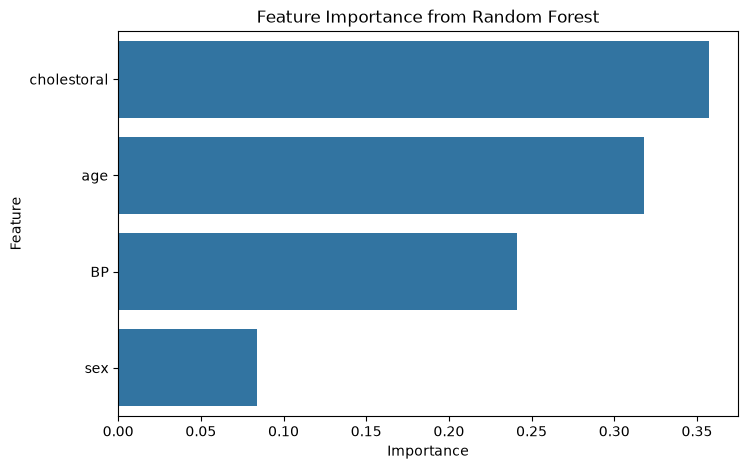

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x='Imp', y='Varname', data=imp_df)
plt.title('Feature Importance from Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()
